In [1]:
import requests
import enum
import json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import time


In [19]:
from baybe import Campaign
from baybe.objectives import SingleTargetObjective, DesirabilityObjective, ParetoObjective
from baybe.parameters import (
    CategoricalParameter,
    NumericalDiscreteParameter,
    SubstanceParameter,
    NumericalContinuousParameter
)
import torch
from baybe.recommenders import RandomRecommender, BotorchRecommender, TwoPhaseMetaRecommender, SequentialMetaRecommender, FPSRecommender
from baybe.surrogates import RandomForestSurrogate
from baybe.acquisition import qLogNoisyExpectedHypervolumeImprovement,qLogNoisyExpectedImprovement,qKnowledgeGradient,qThompsonSampling,qLogExpectedImprovement,PosteriorStandardDeviation,qPosteriorStandardDeviation, LogExpectedImprovement,UpperConfidenceBound
from baybe.searchspace import SearchSpace,SubspaceDiscrete
from baybe.targets import NumericalTarget
from botorch.utils.multi_objective.box_decompositions.dominated import (
    DominatedPartitioning,
)
from baybe.constraints import (
    DiscreteExcludeConstraint,
    ThresholdCondition,
    SubSelectionCondition,
)
import seaborn as sns
from matplotlib import pyplot as plt
import plotly
import plotly.express as px
import plotly.graph_objects as go
import paretoset 
import os

os.environ['BAYBE_CACHE_DIR']='' # turn descriptor caching off
from baybe.utils.random import set_random_seed
set_random_seed(1337)

In [3]:
df_data = pd.read_csv('./result_trimmed.csv')

In [4]:
df_data = df_data.drop(7).copy()

In [5]:
df_data.columns

Index(['current_mA', 'sub_concentration_M', 'acetate_concentration_M',
       'solvent_ratio', 'yield', 'log_yield'],
      dtype='object')

In [7]:
#df_data

In [8]:
df_data_yield = df_data.drop(columns='log_yield')
df_data_logyield = df_data.drop(columns='yield')
df_data_yield.columns = ['current_mA', 'sub_concentration_M', 'acetate_concentration_M','solvent_ratio', 'response']
df_data_logyield.columns = ['current_mA', 'sub_concentration_M', 'acetate_concentration_M','solvent_ratio', 'response']

df_data_yield = df_data_yield[['acetate_concentration_M', 'current_mA', 'solvent_ratio','sub_concentration_M','response']].copy()
df_data_logyield = df_data_logyield[['acetate_concentration_M', 'current_mA', 'solvent_ratio','sub_concentration_M','response']].copy()

<Axes: >

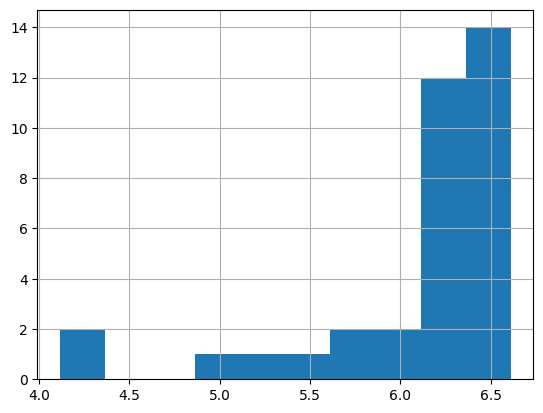

In [9]:
df_data_logyield.response.hist()

<Axes: >

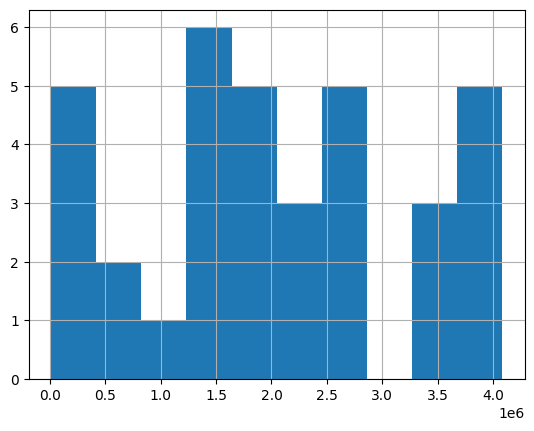

In [10]:
df_data_yield.response.hist()

In [11]:
current_mA_array = np.linspace(3,20,35)
sub_concentration_M_array  = np.linspace(0.1,0.4,13)
acetate_concentration_M_array = np.linspace(0.25,0.8,12)
solvent_ratio_array  = np.linspace(0,80,9)

In [12]:
#### parameter space we introduce tolerance to deal with numerical issues when reading data from a df
current_mA = NumericalDiscreteParameter(name='current_mA',values=current_mA_array,tolerance=0.001)
sub_concentration_M = NumericalDiscreteParameter(name='sub_concentration_M',values=sub_concentration_M_array,tolerance=0.001)
acetate_concentration_M = NumericalDiscreteParameter(name='acetate_concentration_M',values=acetate_concentration_M_array,tolerance=0.001)
solvent_ratio = NumericalDiscreteParameter(name='solvent_ratio',values=solvent_ratio_array,tolerance=0.1)


In [13]:
# we create the searchspace  and define the objective and direction of optimization = MAX
searchspace = SearchSpace.from_product(parameters=[current_mA,sub_concentration_M,acetate_concentration_M,solvent_ratio])

target   = NumericalTarget(name="response",mode="MAX")### redefine accordin to new API
objective = SingleTargetObjective(target=target)

In [17]:
searchspace.comp_rep_columns

('acetate_concentration_M',
 'current_mA',
 'solvent_ratio',
 'sub_concentration_M')

In [18]:
### we reorder the columns of the dataset according to the searchspace
df_data_yield = df_data_yield[['acetate_concentration_M', 'current_mA', 'solvent_ratio','sub_concentration_M','response']].copy()
df_data_logyield = df_data_logyield[['acetate_concentration_M', 'current_mA', 'solvent_ratio','sub_concentration_M','response']].copy()

In [23]:
#campaign_master = Campaign(objective=objective,searchspace=searchspace)
#campaign_master.add_measurements(df_data_yield)
#campaign_master.recommend(1)

In [24]:
#### loops that return the values of the acquisition function LogEI for eachvalue of the current and a recommendation of 6 new conditions for the other parameters
#### we use the version of LogEI that handles better noisy data
campaign_master = Campaign(objective=objective,searchspace=searchspace,recommender=BotorchRecommender(acquisition_function=qLogNoisyExpectedImprovement()))
#campaign_master = Campaign(objective=objective,searchspace=searchspace)
import warnings
import random
from baybe.exceptions import UnusedObjectWarning
from copy import deepcopy
from IPython.display import clear_output, display

solutions    = pd.DataFrame(columns=['acetate_concentration_M', 'current_mA', 'solvent_ratio','sub_concentration_M','acquisition_function'])#,'R^2','MAE'])


warnings.filterwarnings("ignore")
batch_size = 6
best_joint_acqf = -np.inf
best_experiments = None
all_currents = list(current_mA_array)

for current in all_currents:
    current_excluded = [c for c in all_currents if c!= current]
    constraint = DiscreteExcludeConstraint(
            parameters=["current_mA"],
            conditions=[SubSelectionCondition(selection=current_excluded)]
        )
    campaign_tmp = deepcopy(campaign_master)
    campaign_tmp.add_measurements(df_data_yield)
    campaign_tmp.toggle_discrete_candidates(constraints=[constraint], exclude = True, complement = True)
    experiments = campaign_tmp.recommend(batch_size = batch_size)
    experiments = experiments[['acetate_concentration_M', 'current_mA', 'solvent_ratio','sub_concentration_M']].copy()
    cur_val = campaign_tmp.joint_acquisition_value(experiments)
    experiments['acquisition_function'] = cur_val
    solutions = pd.concat([solutions,experiments])
    #print(f"The EI over the best Yield for a new row at current current_mA = {current} is {np.exp(cur_val):.2f}")
    print(f"The EI over the best Yield for a new row at current current_mA = {current} is {cur_val:.2f}")
   # print(experiments)

solutions.to_csv('./recommendations_batch6.csv')

The EI over the best Yield for a new row at current current_mA = 3.0 is 12.62
The EI over the best Yield for a new row at current current_mA = 3.5 is 12.85
The EI over the best Yield for a new row at current current_mA = 4.0 is 13.09
The EI over the best Yield for a new row at current current_mA = 4.5 is 13.28
The EI over the best Yield for a new row at current current_mA = 5.0 is 13.46
The EI over the best Yield for a new row at current current_mA = 5.5 is 13.58
The EI over the best Yield for a new row at current current_mA = 6.0 is 13.64
The EI over the best Yield for a new row at current current_mA = 6.5 is 13.60
The EI over the best Yield for a new row at current current_mA = 7.0 is 13.38
The EI over the best Yield for a new row at current current_mA = 7.5 is 12.85
The EI over the best Yield for a new row at current current_mA = 8.0 is 12.20
The EI over the best Yield for a new row at current current_mA = 8.5 is 11.84
The EI over the best Yield for a new row at current current_mA =

In [25]:
from baybe.insights import SHAPInsight
insight = SHAPInsight.from_campaign(campaign_tmp)


  0%|          | 0/35 [00:00<?, ?it/s]

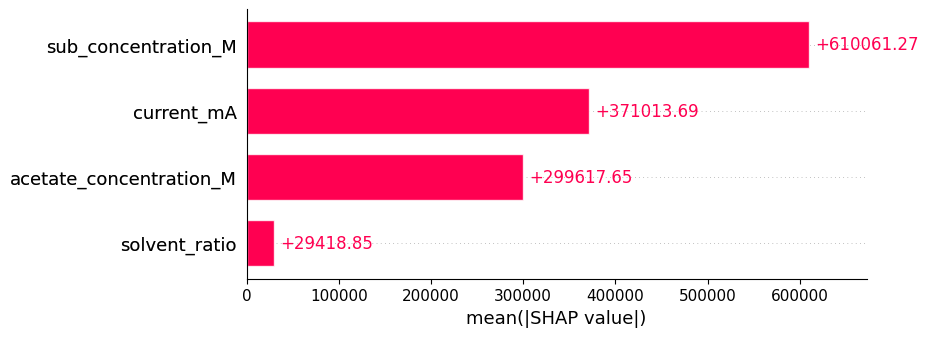

In [26]:
insight.plot("bar")


  0%|          | 0/35 [00:00<?, ?it/s]

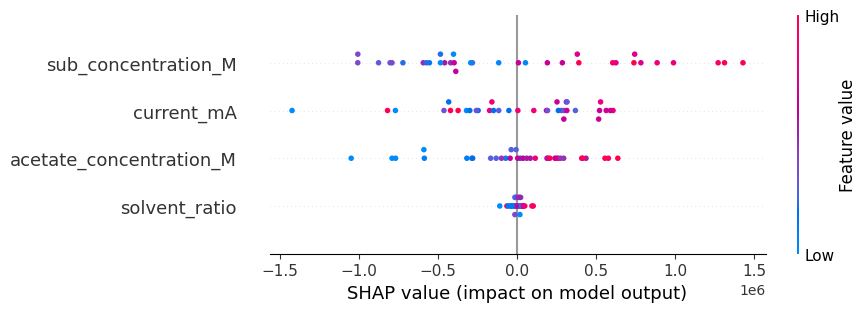

In [27]:
insight.plot("beeswarm")


In [31]:
#### Check cross validation of the model and comparesit with Vanilla settings in BOtorch. to run this run the last to cell at the ends where the function is defined
df = df_data_yield.copy()
DIM_LIMITS = (8, 75)
X_np = df.iloc[:, :-1].to_numpy(dtype=float)
Y_np = df.iloc[:, -1].to_numpy(dtype=float).reshape(-1, 1)

mins = torch.tensor(searchspace.discrete.comp_rep.min(axis=0), dtype=torch.double)
maxs = torch.tensor(searchspace.discrete.comp_rep.max(axis=0), dtype=torch.double)
bounds = torch.vstack([mins, maxs])

X = torch.tensor(X_np, dtype=torch.double)
Y = torch.tensor(Y_np, dtype=torch.double)

d = X.shape[-1]

gamma_outputscale  =(
            np.interp(d,DIM_LIMITS, [5.0, 3.5]),
            np.interp(d,DIM_LIMITS, [0.5, 0.15]),
        )
gamma_lengthscale =(
            np.interp(d,DIM_LIMITS, [1.2, 2.5]),
            np.interp(d,DIM_LIMITS, [1.1, 0.55]),
        )

#gamma_lengthscale =(
#            3.0,
#            6.0,
#        )

gamma_noise        =(
            np.interp(d,DIM_LIMITS, [1.05, 1.5]),
            np.interp(d,DIM_LIMITS, [0.5, 0.1]),
        )

ls_init = torch.tensor(np.interp(d,DIM_LIMITS, [0.2, 6.0]), dtype=torch.double)  # ARD lengthscales
os_init = np.interp(d,DIM_LIMITS, [8.0, 15.0])  # outputscale variance initial value
noise_init = np.interp(d,DIM_LIMITS, [0.1, 5.0])

results = run_models_from_df(
        df=df,
        bounds=bounds,
        gamma_outputscale=gamma_outputscale,
        gamma_lengthscale=gamma_lengthscale,
        gamma_noise=gamma_noise,
        lengthscale_initial_value=ls_init,
        outputscale_initial_value=os_init,
        noise_initial_value=noise_init,
    )

for name, res in results.items():
    print(f"{name}: RMSE={res['rmse'].item():.4f}  MAE={res['mae'].item():.4f}")



Vanilla GP:
Hyperparameters (original units):
- lengthscale dim 0: 0.158512
- lengthscale dim 1: 1.42324
- lengthscale dim 2: 0.485591
- lengthscale dim 3: 0.0883906
- outputscale std: (no ScaleKernel; not applicable)
- noise std: 102134

Custom Matérn with Gamma priors:
Hyperparameters (original units):
- lengthscale dim 0: 0.544559
- lengthscale dim 1: 0.17648
- lengthscale dim 2: 1.89258
- lengthscale dim 3: 0.247762
- outputscale std: 1.3449e+06
- noise std: 41492.5
vanilla: RMSE=888077.0732  MAE=664503.4132
custom_matern: RMSE=757329.2166  MAE=602144.3538


R2 (Vanilla): 0.4482
R2 (Custom):  0.5988


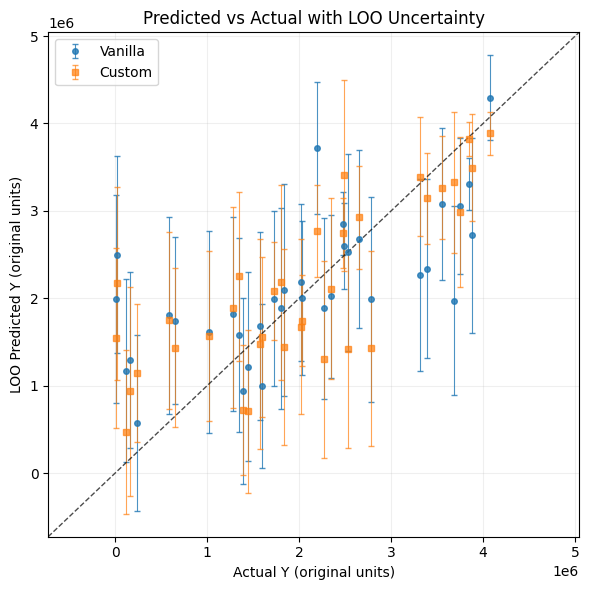

In [32]:
### parity plot of the cross validation leave one out done above

def r2_score_from_loo(y_true: torch.Tensor, y_pred: torch.Tensor) -> float:
    """
    y_true, y_pred: [n,1] tensors in original units (CPU or CUDA ok).
    Returns float R^2.
    """
    y_true = y_true.view(-1, 1)
    y_pred = y_pred.view(-1, 1)
    sst = torch.sum((y_true - y_true.mean()) ** 2)
    sse = torch.sum((y_true - y_pred) ** 2)
    if sst.item() == 0.0:
        return float("nan")
    r2 = 1.0 - (sse / sst)
    return float(r2.item())
import matplotlib.pyplot as plt
import numpy as np

def plot_pred_vs_actual_with_uncertainty(
    y_true: torch.Tensor,
    pred1_mean: torch.Tensor,
    pred1_std: torch.Tensor,
    pred2_mean: torch.Tensor = None,
    pred2_std: torch.Tensor = None,
    labels=("Vanilla", "Custom"),
    std_mult: float = 1.0,
    title: str = "Predicted vs Actual (LOO)",
    figsize=(6, 6),
):
    """
    y_true, pred*_mean, pred*_std: [n,1] tensors in original units.
    std_mult: number of stds for error bars (1 -> ~68%, 2 -> ~95%).
    """
    y_true_np = y_true.detach().cpu().numpy().reshape(-1)
    m1 = pred1_mean.detach().cpu().numpy().reshape(-1)
    s1 = pred1_std.detach().cpu().numpy().reshape(-1)

    plt.figure(figsize=figsize)
    # Determine axis limits from data and uncertainty
    all_vals = [y_true_np, m1, m1 - std_mult * s1, m1 + std_mult * s1]
    colors = ["tab:blue", "tab:orange"]
    markers = ["o", "s"]

    # First model
    plt.errorbar(
        y_true_np,
        m1,
        yerr=std_mult * s1,
        fmt=markers[0],
        ms=4,
        alpha=0.8,
        color=colors[0],
        ecolor=colors[0],
        elinewidth=0.8,
        capsize=2,
        label=labels[0],
        linestyle="none",
    )

    # Optional second model
    if pred2_mean is not None and pred2_std is not None:
        m2 = pred2_mean.detach().cpu().numpy().reshape(-1)
        s2 = pred2_std.detach().cpu().numpy().reshape(-1)
        plt.errorbar(
            y_true_np,
            m2,
            yerr=std_mult * s2,
            fmt=markers[1],
            ms=4,
            alpha=0.7,
            color=colors[1],
            ecolor=colors[1],
            elinewidth=0.8,
            capsize=2,
            label=labels[1],
            linestyle="none",
        )
        all_vals += [m2, m2 - std_mult * s2, m2 + std_mult * s2]

    # y=x reference line
    all_vals = np.concatenate([v.reshape(-1, 1) for v in all_vals], axis=0)
    vmin = np.nanmin(all_vals)
    vmax = np.nanmax(all_vals)
    pad = 0.05 * (vmax - vmin + 1e-12)
    lo, hi = vmin - pad, vmax + pad
    plt.plot([lo, hi], [lo, hi], "k--", linewidth=1, alpha=0.7)

    plt.xlabel("Actual Y (original units)")
    plt.ylabel("LOO Predicted Y (original units)")
    plt.title(title)
    plt.legend()
    plt.grid(True, alpha=0.2)
    plt.xlim(lo, hi)
    plt.ylim(lo, hi)
    plt.tight_layout()
    plt.show()
# After results = run_models_from_df(...)
Y = torch.tensor(df.iloc[:, -1].to_numpy(float).reshape(-1, 1), dtype=torch.double)

v_mean = results["vanilla"]["loo_mean"]
v_std  = results["vanilla"]["loo_std"]
c_mean = results["custom_matern"]["loo_mean"]
c_std  = results["custom_matern"]["loo_std"]

# Compute and print R2
r2_vanilla = r2_score_from_loo(Y, v_mean)
r2_custom  = r2_score_from_loo(Y, c_mean)
print(f"R2 (Vanilla): {r2_vanilla:.4f}")
print(f"R2 (Custom):  {r2_custom:.4f}")

# Plot predicted vs actual with uncertainty (±1 std by default; use std_mult=2 for ~95%)
plot_pred_vs_actual_with_uncertainty(
    y_true=Y,
    pred1_mean=v_mean,
    pred1_std=v_std,
    pred2_mean=c_mean,
    pred2_std=c_std,
    labels=("Vanilla", "Custom"),
    std_mult=1.0,
    title="Predicted vs Actual with LOO Uncertainty",
)

In [33]:
#campaign_master = Campaign(objective=objective,searchspace=searchspace)
#campaign_master.add_measurements(df_data_yield)
#campaign_master.recommend(1)

Red dots will not be displayed.


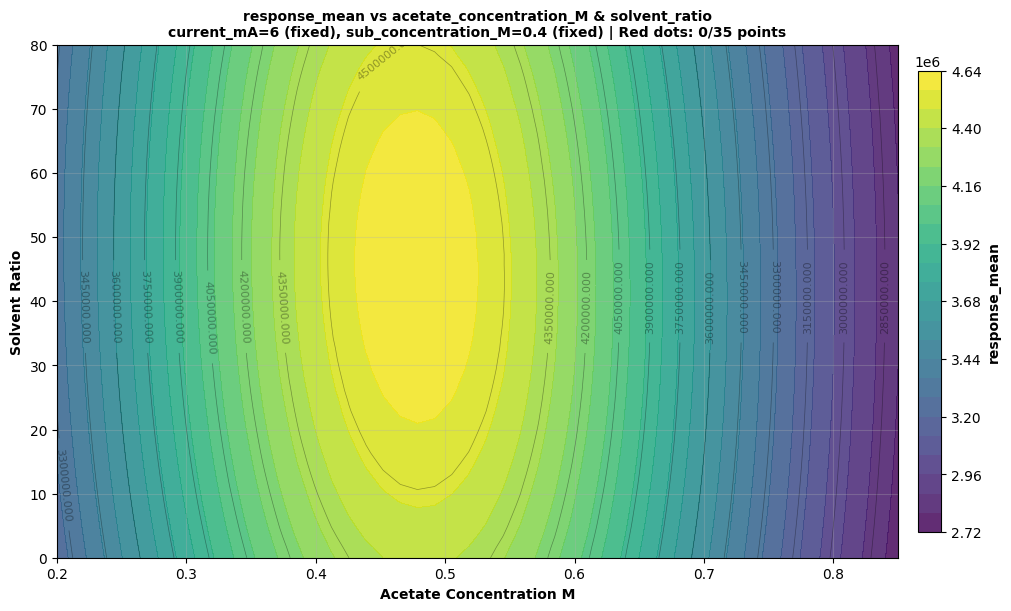

In [36]:
## uses the full model built during the plate design above to inspect the contour plots. The model information is extracted from the object campaign_tmp
#Example usage with categorical variables
#categorical_vars = {
#    'Ligand': 'SCHEMBL15068049',
#    'Solvent': 'n-Butyl acetate',
#    'Base': 'Potassium pivalate'
#}
#campaign_master = Campaign(objective=objective,searchspace=searchspace)



initial_design = df_data_yield.copy()

fixed_numerical_vars = {
    'sub_concentration_M': 0.4,  # 
    'current_mA': 6.      # 
}

bounds_params = {
        'acetate_concentration_M': (0.2, 0.85),
        'sub_concentration_M': (0.05, 0.45),
        'solvent_ratio': (0, 80),
        'current_mA': (3,20)
}

fig, axes = create_contour_plots(
    method_name='posterior_stats',
    campaign=campaign_tmp,
    df_input_points=initial_design,#pd.concat([initial_design,measurements]),
    target_stat = 'mean',
    bounds=bounds_params,
    input_cols=['acetate_concentration_M','current_mA','solvent_ratio','sub_concentration_M'],
    varying_pairs=[('acetate_concentration_M','solvent_ratio')],
    categorical_vars=None,
    fixed_numerical_vars = fixed_numerical_vars,
    numerical_tolerance={'sub_concentration_M': 0.01,'current_mA': 0.01,'solvent_ratio': 0.01,'acetate_concentration_M': 0.01},  # Custom tolerances
    response_names=['response'],
    filter_red_dots_by_fixed=True
)

In [29]:
import torch
import pandas as pd
from typing import Tuple, Dict

from gpytorch.kernels import MaternKernel, ScaleKernel
from gpytorch.priors import GammaPrior
from gpytorch.likelihoods import GaussianLikelihood
from gpytorch.mlls import ExactMarginalLogLikelihood

from botorch.models.gp_regression import SingleTaskGP
from botorch.models.transforms.input import Normalize
from botorch.models.transforms.outcome import Standardize
from botorch.fit import fit_gpytorch_mll


# ----------------------- Safe getters -----------------------

def get_lengthscale_and_outputscale(model: SingleTaskGP):
    cm = model.covar_module
    if hasattr(cm, "base_kernel") and hasattr(cm.base_kernel, "lengthscale"):
        lengthscale = cm.base_kernel.lengthscale.detach().cpu().view(-1)
    elif hasattr(cm, "lengthscale"):
        lengthscale = cm.lengthscale.detach().cpu().view(-1)
    else:
        raise AttributeError("Covariance module doesn't expose a 'lengthscale' parameter.")
    outputscale_var = None
    if hasattr(cm, "outputscale"):
        outputscale_var = float(cm.outputscale.detach().cpu().item())
    return lengthscale, outputscale_var


def get_output_mean_std(model: SingleTaskGP):
    """
    Get (y_mean, y_std) as tensors [1,1] on CPU.
    Priority:
      1) Try outcome_transform buffers (mean/std or means/stds)
      2) Try outcome_transform.state_dict for keys
      3) Fallback to raw training Y stats stored on model._raw_train_Y
      4) If none available, use (0, 1)
    """
    # 1) direct attributes
    ot = getattr(model, "outcome_transform", None)
    if ot is not None:
        for mean_attr, std_attr in [("mean", "std"), ("means", "stds")]:
            if hasattr(ot, mean_attr) and hasattr(ot, std_attr):
                y_mean = getattr(ot, mean_attr)
                y_std = getattr(ot, std_attr)
                y_mean = y_mean.detach().reshape(1, 1).cpu()
                y_std = y_std.detach().reshape(1, 1).cpu().clamp_min(1e-12)
                return y_mean, y_std
        # 2) try state_dict
        try:
            sd = ot.state_dict()
            # common possible keys
            for mkey, skey in [("mean", "std"), ("means", "stds")]:
                if mkey in sd and skey in sd:
                    y_mean = sd[mkey].detach().reshape(1, 1).cpu()
                    y_std = sd[skey].detach().reshape(1, 1).cpu().clamp_min(1e-12)
                    return y_mean, y_std
        except Exception:
            pass

    # 3) fallback to raw Y stats stored on model
    raw_Y = getattr(model, "_raw_train_Y", None)
    if raw_Y is not None:
        y_mean = torch.mean(raw_Y).view(1, 1).cpu()
        y_std = torch.std(raw_Y, unbiased=True).clamp_min(1e-12).view(1, 1).cpu()
        return y_mean, y_std

    # 4) default
    return torch.zeros(1, 1), torch.ones(1, 1)


# ----------------------- Models -----------------------

class VanillaGP(SingleTaskGP):
    def __init__(self, train_X: torch.Tensor, train_Y: torch.Tensor, bounds: torch.Tensor):
        super().__init__(
            train_X=train_X,
            train_Y=train_Y,
            input_transform=Normalize(train_X.shape[-1], bounds=bounds, transform_on_train=True, transform_on_eval=True),
            outcome_transform=Standardize(m=1),
        )
        # Store raw Y for fallback unstandardization
        self._raw_train_Y = train_Y.clone()
        self.to(train_X)


class CustomMaternGP(SingleTaskGP):
    def __init__(
        self,
        train_X: torch.Tensor,
        train_Y: torch.Tensor,
        bounds: torch.Tensor,
        outputscale_prior: GammaPrior,
        lengthscale_prior: GammaPrior,
        noise_prior: GammaPrior,
        lengthscale_initial_value: torch.Tensor,   # normalized-X space; shape [d] or [1,d]
        outputscale_initial_value: float,          # standardized-Y space; variance
        noise_initial_value: float,                # standardized-Y space; variance
        nu: float = 2.5,
    ):
        super().__init__(
            train_X=train_X,
            train_Y=train_Y,
            input_transform=Normalize(train_X.shape[-1], bounds=bounds, transform_on_train=True, transform_on_eval=True),
            outcome_transform=Standardize(m=1),
        )
        # Store raw Y for fallback unstandardization
        self._raw_train_Y = train_Y.clone()

        d = train_X.shape[-1]
        base = MaternKernel(nu=nu, ard_num_dims=d)
        base.register_prior("lengthscale_prior", lengthscale_prior, "lengthscale")
        self.covar_module = ScaleKernel(base, outputscale_prior=outputscale_prior)

        ls_init = lengthscale_initial_value
        if ls_init.ndim == 1:
            ls_init = ls_init.reshape(1, -1)
        self.covar_module.base_kernel.lengthscale = ls_init.to(train_X)
        self.covar_module.outputscale = torch.tensor(outputscale_initial_value, dtype=train_X.dtype, device=train_X.device)

        self.likelihood = GaussianLikelihood(noise_prior=noise_prior)
        self.likelihood.noise = torch.tensor(noise_initial_value, dtype=train_X.dtype, device=train_X.device)

        self.to(train_X)


# ----------------------- Fit -----------------------

def fit_model(model: SingleTaskGP) -> SingleTaskGP:
    mll = ExactMarginalLogLikelihood(model.likelihood, model).to(model.train_inputs[0])
    fit_gpytorch_mll(mll)
    model.eval()
    model.likelihood.eval()
    return model


# ----------------------- LOO CV (returns stds in original units) -----------------------

@torch.no_grad()
def loo_cv_from_fitted_model(model: SingleTaskGP):
    """
    Efficient leave-one-out predictive mean and std in original Y units (no refitting).
    Uses robust mean/std extraction; falls back to raw Y stats if transform buffers unavailable.
    """
    X = model.train_inputs[0]
    Y_t = model.train_targets.unsqueeze(-1)  # [n,1]
    n = Y_t.shape[0]
    device, dtype = X.device, X.dtype

    K_f = model.covar_module(X).evaluate()
    sigma2 = model.likelihood.noise
    K = K_f + sigma2 * torch.eye(n, device=device, dtype=dtype)

    L = torch.linalg.cholesky(K)
    alpha = torch.cholesky_solve(Y_t, L)

    I = torch.eye(n, device=device, dtype=dtype)
    Linv = torch.linalg.solve_triangular(L, I, upper=False)
    v = (Linv ** 2).sum(dim=0, keepdim=True).t()

    loo_var_t = 1.0 / v
    loo_mean_t = Y_t - alpha / v

    # Robust unstandardization
    y_mean, y_std = get_output_mean_std(model)
    loo_mean = loo_mean_t.cpu() * y_std + y_mean
    loo_std = torch.sqrt(loo_var_t.cpu()) * y_std

    return loo_mean, loo_std


# ----------------------- Hyperparams printing (stds) -----------------------

def print_hyperparams_stds_in_original_units_with_bounds(model: SingleTaskGP, bounds: torch.Tensor):
    lengthscale, outputscale_var = get_lengthscale_and_outputscale(model)
    noise_var = float(model.likelihood.noise.detach().cpu().item())

    mins = bounds[0].detach().cpu().view(-1)
    maxs = bounds[1].detach().cpu().view(-1)
    Xrange = (maxs - mins).clamp_min(1e-12)

    if lengthscale.numel() == 1:
        #ls_orig = lengthscale * Xrange.mean()
        ls_orig = lengthscale
    else:
        #ls_orig = lengthscale[: Xrange.numel()] * Xrange
        ls_orig = lengthscale[: Xrange.numel()]

    y_mean, y_std = get_output_mean_std(model)
    y_std_scalar = float(y_std.item())

    outputscale_std_orig = None
    if outputscale_var is not None:
        outputscale_std_orig = (outputscale_var ** 0.5) * y_std_scalar
    noise_std_orig = (noise_var ** 0.5) * y_std_scalar

    print("Hyperparameters (original units):")
    if lengthscale.numel() == 1:
        print(f"- lengthscale (isotropic): {ls_orig.item():.6g}")
    else:
        for i in range(Xrange.numel()):
            print(f"- lengthscale dim {i}: {ls_orig[i].item():.6g}")
    if outputscale_std_orig is not None:
        print(f"- outputscale std: {outputscale_std_orig:.6g}")
    else:
        print("- outputscale std: (no ScaleKernel; not applicable)")
    print(f"- noise std: {noise_std_orig:.6g}")


# ----------------------- Orchestration from DataFrame -----------------------

def run_models_from_df(
    df: pd.DataFrame,
    bounds: torch.Tensor,  # shape [2, d] in original units
    gamma_outputscale: Tuple[float, float] = (2.0, 1.0),
    gamma_lengthscale: Tuple[float, float] = (2.0, 1.0),
    gamma_noise: Tuple[float, float] = (1.1, 0.05),
    lengthscale_initial_value: torch.Tensor = None,  # normalized X space
    outputscale_initial_value: float = 1.0,          # standardized Y space (variance)
    noise_initial_value: float = 0.05,               # standardized Y space (variance)
    seed: int = 0,
) -> Dict[str, Dict[str, torch.Tensor]]:
    torch.manual_seed(seed)

    X_np = df.iloc[:, :-1].to_numpy(dtype=float)
    Y_np = df.iloc[:, -1].to_numpy(dtype=float).reshape(-1, 1)

    X = torch.tensor(X_np, dtype=torch.double)
    Y = torch.tensor(Y_np, dtype=torch.double)

    d = X.shape[-1]
    assert bounds.shape == (2, d), "bounds must be [2, d] with mins and maxs"

    out_prior = GammaPrior(concentration=gamma_outputscale[0], rate=gamma_outputscale[1])
    len_prior = GammaPrior(concentration=gamma_lengthscale[0], rate=gamma_lengthscale[1])
    noise_prior = GammaPrior(concentration=gamma_noise[0], rate=gamma_noise[1])

    if lengthscale_initial_value is None:
        lengthscale_initial_value = torch.full((d,), 0.3, dtype=X.dtype, device=X.device)

    # Fit vanilla
    vanilla = fit_model(VanillaGP(X, Y, bounds))
    v_mean, v_std = loo_cv_from_fitted_model(vanilla)
    v_rmse = torch.sqrt(torch.mean((Y.cpu() - v_mean) ** 2))
    v_mae = torch.mean(torch.abs(Y.cpu() - v_mean))

    print("\nVanilla GP:")
    print_hyperparams_stds_in_original_units_with_bounds(vanilla, bounds)

    # Fit custom
    custom = fit_model(CustomMaternGP(
        train_X=X,
        train_Y=Y,
        bounds=bounds,
        outputscale_prior=out_prior,
        lengthscale_prior=len_prior,
        noise_prior=noise_prior,
        lengthscale_initial_value=lengthscale_initial_value,
        outputscale_initial_value=outputscale_initial_value,
        noise_initial_value=noise_initial_value,
        nu=2.5,
    ))
    c_mean, c_std = loo_cv_from_fitted_model(custom)
    c_rmse = torch.sqrt(torch.mean((Y.cpu() - c_mean) ** 2))
    c_mae = torch.mean(torch.abs(Y.cpu() - c_mean))

    print("\nCustom Matérn with Gamma priors:")
    print_hyperparams_stds_in_original_units_with_bounds(custom, bounds)

    return {
        "vanilla": {"loo_mean": v_mean, "loo_std": v_std, "rmse": v_rmse, "mae": v_mae, "model": vanilla},
        "custom_matern": {"loo_mean": c_mean, "loo_std": c_std, "rmse": c_rmse, "mae": c_mae, "model": custom},
    }

In [30]:
from scipy.interpolate import griddata
def create_contour_plots(
    campaign,
    method_name,
    df_input_points: pd.DataFrame,
    bounds: dict,
    input_cols,                # >=2 inputs
    response_names=('response1',),        # one or more responses (rows if posterior_stats)
    target_stat='mean',
    varying_pairs=None,                # list of (x_var, y_var) 2D slices or a single 2-tuple
    categorical_vars=None,             # dict mapping categorical var names to chosen category
    fixed_numerical_vars=None,         # dict mapping numerical var names to fixed values
    filter_red_dots_by_fixed=True,     # NEW: whether to filter red dots by fixed variables
    numerical_tolerance=None,          # NEW: tolerance for numerical filtering (default: 10% of range)
    grid_resolution=50,
    interpolation_method='cubic',
    figsize=(10, 6),                # base size; height will scale by #rows
    plot_red_dots=True,                # toggle red dots
    red_dot_min=50,                # min dot size (posterior_stats)
    red_dot_max=250,                # max dot size (posterior_stats)
    red_dot_constant_size=60,             # constant size when method_name='acqf_values'
    legend_response_name=None,            # which response to use for shared legend (default uses first)
):
    """
    Contour plots for BO predictions or ACQF across multiple 2D slices.
    - Remaining inputs (not in the current varying pair) are fixed to:
      * Specified values for categorical variables (categorical_vars)
      * Specified values for numerical variables (fixed_numerical_vars)
      * Dataset means for numerical variables not specified in fixed_numerical_vars
    - Red dots: if plot_red_dots=True, plot data points that match the fixed conditions.
      For posterior_stats, dot size is proportional to the corresponding response value.
      For acqf_values, a constant size is used.
    - Adds ONE shared legend on the right for red-dot size mapping (min/mid/max).
    - Uses constrained_layout and per-row dynamic height to avoid vertical overlap.
    
    Parameters:
    -----------
    categorical_vars : dict, optional
        Dictionary mapping categorical variable names to their chosen category values.
        Example: {'catalyst': 'Pd', 'solvent': 'THF'}
        If None, all variables are treated as numerical.
        Note: Categorical variables should NOT be included in the bounds dictionary.
    
    fixed_numerical_vars : dict, optional
        Dictionary mapping numerical variable names to their fixed values.
        Example: {'temperature': 100, 'pressure': 2.5}
        If a numerical variable is not in this dict and not in varying_pairs,
        it will be fixed to its mean value from df_input_points.
    
    filter_red_dots_by_fixed : bool, default True
        Whether to filter red dots to only show data points that match fixed conditions.
        If False, shows all data points regardless of fixed variable values.
    
    numerical_tolerance : dict or float, optional
        Tolerance for filtering numerical variables. Can be:
        - dict: mapping variable names to specific tolerances
        - float: single tolerance applied to all numerical variables
        - None: uses 10% of each variable's range as default tolerance
    """

    # Normalize and validate input_cols
    if isinstance(input_cols, (tuple, np.ndarray)):
        input_cols = list(input_cols)
    if not isinstance(input_cols, list) or len(input_cols) < 2:
        raise ValueError("input_cols must be a list with at least 2 input names.")

    missing_in_df = [c for c in input_cols if c not in df_input_points.columns]
    if missing_in_df:
        raise ValueError(f"input_cols missing in df_input_points: {missing_in_df}")

    # Handle categorical and fixed numerical variables
    if categorical_vars is None:
        categorical_vars = {}
    if fixed_numerical_vars is None:
        fixed_numerical_vars = {}
    
    # Separate numerical and categorical variables
    numerical_vars = [c for c in input_cols if c not in categorical_vars]
    
    # Check that numerical variables are in bounds
    missing_in_bounds = [c for c in numerical_vars if c not in bounds]
    if missing_in_bounds:
        raise ValueError(f"Numerical input_cols missing in bounds: {missing_in_bounds}")
    
    # Validate categorical variables
    for cat_var, cat_value in categorical_vars.items():
        if cat_var not in input_cols:
            raise ValueError(f"Categorical variable '{cat_var}' not found in input_cols")
        if cat_var not in df_input_points.columns:
            raise ValueError(f"Categorical variable '{cat_var}' not found in df_input_points")
        # Check if the specified category exists in the data
        available_categories = df_input_points[cat_var].unique()
        if cat_value not in available_categories:
            raise ValueError(f"Category '{cat_value}' not found for variable '{cat_var}'. "
                           f"Available categories: {list(available_categories)}")

    # Validate fixed numerical variables
    for num_var, num_value in fixed_numerical_vars.items():
        if num_var not in input_cols:
            raise ValueError(f"Fixed numerical variable '{num_var}' not found in input_cols")
        if num_var in categorical_vars:
            raise ValueError(f"Variable '{num_var}' cannot be both categorical and fixed numerical")
        if num_var not in bounds:
            raise ValueError(f"Fixed numerical variable '{num_var}' must have bounds defined")
        # Validate that the fixed value is within bounds
        var_min, var_max = bounds[num_var]
        if not (var_min <= num_value <= var_max):
            raise ValueError(f"Fixed value {num_value} for '{num_var}' is outside bounds [{var_min}, {var_max}]")

    # Responses / targets
    if isinstance(response_names, str):
        response_names = [response_names]
    response_names = list(response_names)

    if method_name == 'acquisition_values':
        display_variable = 'Acquisition Function Values'
    elif method_name == 'posterior_stats':
        display_variable = f'Posterior Stats ({target_stat})'
        if plot_red_dots:
            missing_resp = [r for r in response_names if r not in df_input_points.columns]
            if missing_resp:
                raise ValueError(f"Missing response columns in df_input_points for red dot sizing: {missing_resp}")
    else:
        raise TypeError("method_name must be 'posterior_stats' or 'acqf_values'.")

    campaign_method = getattr(campaign, method_name)

    # Normalize varying_pairs (allow single 2-tuple or list of 2-tuples)
    if varying_pairs is None:
        # Default to first two numerical variables if available
        if len(numerical_vars) >= 2:
            varying_pairs = [(numerical_vars[0], numerical_vars[1])]
        else:
            raise ValueError("Need at least 2 numerical variables for varying_pairs when categorical_vars are specified")
    elif isinstance(varying_pairs, tuple) and len(varying_pairs) == 2 and isinstance(varying_pairs[0], str):
        varying_pairs = [varying_pairs]
    elif isinstance(varying_pairs, (list, tuple)):
        varying_pairs = [tuple(vp) for vp in varying_pairs]
    else:
        raise ValueError("varying_pairs must be a 2-tuple or a list of 2-tuples of input column names.")

    bad_pairs = [vp for vp in varying_pairs if not (isinstance(vp, tuple) and len(vp) == 2)]
    if bad_pairs:
        raise ValueError(f"Each entry of varying_pairs must be a 2-tuple. Invalid entries: {bad_pairs}")
    
    # Validate that varying pairs are numerical (have bounds)
    for x_var, y_var in varying_pairs:
        if x_var not in input_cols or y_var not in input_cols:
            raise ValueError(f"Varying pair ({x_var}, {y_var}) must be in input_cols.")
        if x_var in categorical_vars or y_var in categorical_vars:
            raise ValueError(f"Varying pair ({x_var}, {y_var}) cannot contain categorical variables. "
                           f"Only numerical variables can be varied in contour plots.")
        if x_var not in bounds or y_var not in bounds:
            raise ValueError(f"Varying pair ({x_var}, {y_var}) must have bounds defined.")

    # Check for conflicts between varying_pairs and fixed_numerical_vars
    all_varying_vars = set()
    for x_var, y_var in varying_pairs:
        all_varying_vars.update([x_var, y_var])
    
    conflicting_vars = all_varying_vars.intersection(set(fixed_numerical_vars.keys()))
    if conflicting_vars:
        raise ValueError(f"Variables cannot be both varying and fixed: {list(conflicting_vars)}")

    # Filter data for red dots based on fixed variables
    df_filtered_for_dots = df_input_points.copy()
    filter_conditions = []
    
    if plot_red_dots and filter_red_dots_by_fixed:
        # Filter by categorical variables (exact match)
        for cat_var, cat_value in categorical_vars.items():
            df_filtered_for_dots = df_filtered_for_dots[df_filtered_for_dots[cat_var] == cat_value]
            filter_conditions.append(f"{cat_var}={cat_value}")
        
        # Filter by fixed numerical variables (within tolerance)
        if fixed_numerical_vars:
            # Set up tolerances
            if numerical_tolerance is None:
                tolerances = {}
                for num_var in fixed_numerical_vars.keys():
                    var_min, var_max = bounds[num_var]
                    tolerances[num_var] = (var_max - var_min) * 0.1  # 10% of range
            elif isinstance(numerical_tolerance, (int, float)):
                tolerances = {var: numerical_tolerance for var in fixed_numerical_vars.keys()}
            elif isinstance(numerical_tolerance, dict):
                tolerances = numerical_tolerance.copy()
                # Fill in missing tolerances with default
                for num_var in fixed_numerical_vars.keys():
                    if num_var not in tolerances:
                        var_min, var_max = bounds[num_var]
                        tolerances[num_var] = (var_max - var_min) * 0.1
            else:
                raise ValueError("numerical_tolerance must be None, a number, or a dict")
            
            # Apply numerical filters
            for num_var, num_value in fixed_numerical_vars.items():
                tolerance = tolerances[num_var]
                mask = (df_filtered_for_dots[num_var] >= num_value - tolerance) & \
                       (df_filtered_for_dots[num_var] <= num_value + tolerance)
                df_filtered_for_dots = df_filtered_for_dots[mask]
                filter_conditions.append(f"{num_var}={num_value:.3g}±{tolerance:.3g}")
        
        if df_filtered_for_dots.empty:
            filter_desc = ", ".join(filter_conditions) if filter_conditions else "specified conditions"
            print(f"Warning: No data points match the {filter_desc}")
            print("Red dots will not be displayed.")
            plot_red_dots = False

    # Layout: rows = number of responses (posterior), columns = number of varying pairs
    n_rows = len(response_names) if method_name == 'posterior_stats' else 1
    n_cols = len(varying_pairs)

    # Dynamic figure height to prevent vertical overlap
    base_w, base_h = figsize
    per_row_height = max(3.0, base_h)              # ensure at least ~3 inches per row
    figsize_dyn = (base_w, per_row_height * n_rows)

    # Use constrained_layout for robust spacing
    fig, axes = plt.subplots(n_rows, n_cols, figsize=figsize_dyn, squeeze=False, constrained_layout=True)

    # Precompute fixed values for inputs
    fixed_values = {}
    for col in input_cols:
        if col in categorical_vars:
            # Use specified category for categorical variables
            fixed_values[col] = categorical_vars[col]
        elif col in fixed_numerical_vars:
            # Use specified fixed value for numerical variables
            fixed_values[col] = fixed_numerical_vars[col]
        else:
            # Use mean for numerical variables not specified in fixed_numerical_vars
            fixed_values[col] = float(df_input_points[col].mean())

    # Prepare data for shared legend (posterior_stats only) - use filtered data
    legend_handles = None
    if plot_red_dots and method_name == 'posterior_stats':
        legend_resp = legend_response_name or response_names[0]
        vals_full = df_filtered_for_dots[legend_resp].to_numpy()
        vmin_full, vmax_full = np.nanmin(vals_full), np.nanmax(vals_full)
        if np.isfinite(vmin_full) and np.isfinite(vmax_full):
            legend_values = [vmin_full, (vmin_full + vmax_full) / 2.0, vmax_full]
            if vmax_full > vmin_full:
                legend_sizes = [
                    red_dot_min + (val - vmin_full) / (vmax_full - vmin_full) * (red_dot_max - red_dot_min)
                    for val in legend_values
                ]
            else:
                legend_sizes = [(red_dot_min + red_dot_max) / 2.0] * 3

            legend_handles = [
                plt.scatter([], [], c='red', s=s, edgecolors='darkred', alpha=0.85,
                           label=f'{legend_resp} = {val:.3g}')
                for s, val in zip(legend_sizes, legend_values)
            ]

    for col_idx, (x_var, y_var) in enumerate(varying_pairs):
        # Fixed variables for this slice (excluding the varying pair)
        fixed_vars = [c for c in input_cols if c not in (x_var, y_var)]
        fixed_params = {fv: fixed_values[fv] for fv in fixed_vars}

        # Coarse grid (both x_var and y_var are guaranteed to be numerical with bounds)
        x_min, x_max = bounds[x_var]
        y_min, y_max = bounds[y_var]
        coarse_resolution = max(20, grid_resolution // 2)
        x_coarse = np.linspace(x_min, x_max, coarse_resolution)
        y_coarse = np.linspace(y_min, y_max, coarse_resolution)
        X_coarse, Y_coarse = np.meshgrid(x_coarse, y_coarse)

        df_grid_base = pd.DataFrame({
            x_var: X_coarse.ravel(),
            y_var: Y_coarse.ravel(),
        })
        for fp, val in fixed_params.items():
            df_grid_base[fp] = val
        df_grid_base = df_grid_base[input_cols]  # ensure column order expected by model

        # Red dots data: use filtered data that matches fixed conditions
        df_red_base = None
        if plot_red_dots and not df_filtered_for_dots.empty:
            if method_name == 'posterior_stats':
                df_red_base = df_filtered_for_dots[[x_var, y_var] + response_names].copy()
            else:
                df_red_base = df_filtered_for_dots[[x_var, y_var]].copy()

        for row_idx in range(n_rows):
            ax = axes[row_idx, col_idx]

            # Query model for this response (posterior) or ACQF
            output = campaign_method(df_grid_base)

            if method_name == 'acquisition_values':
                Z_coarse = np.asarray(np.round(np.exp(output),2)).reshape(-1)
                target_label = 'ACQF'
            else:
                resp = response_names[row_idx]
                target_variable = f"{resp}_{target_stat}"
                if not isinstance(output, pd.DataFrame):
                    raise TypeError(f"posterior_stats must return a DataFrame. Got {type(output)}")
                if target_variable not in output.columns:
                    raise ValueError(f"Missing '{target_variable}' in posterior output. Available: {list(output.columns)}")
                Z_coarse = output[target_variable].to_numpy().ravel()
                target_label = target_variable

            # Interpolate to fine grid
            x_fine = np.linspace(x_min, x_max, grid_resolution)
            y_fine = np.linspace(y_min, y_max, grid_resolution)
            X_fine, Y_fine = np.meshgrid(x_fine, y_fine)
            points = np.column_stack((X_coarse.ravel(), Y_coarse.ravel()))
            Z_fine = griddata(points, Z_coarse, (X_fine, Y_fine), method=interpolation_method)
            if np.any(np.isnan(Z_fine)):
                Z_near = griddata(points, Z_coarse, (X_fine, Y_fine), method='nearest')
                Z_fine = np.where(np.isnan(Z_fine), Z_near, Z_fine)
                Z_fine = np.round(Z_fine,2)

            # Plot contours
            cf = ax.contourf(X_fine, Y_fine, Z_fine, levels=25, cmap='viridis', alpha=0.85)
            cl = ax.contour(X_fine, Y_fine, Z_fine, levels=15, colors='black', alpha=0.35, linewidths=0.5)
            ax.clabel(cl, inline=True, fontsize=8, fmt='%.3f')

            # Modest colorbar to save vertical space; adjust shrink/pad as needed
            cbar = plt.colorbar(cf, ax=ax, shrink=0.9, pad=0.02)
            cbar.set_label(target_label, fontweight='bold', fontsize=10)

            # Red dots (filtered by fixed variables)
            if plot_red_dots and df_red_base is not None and not df_red_base.empty:
                if method_name == 'posterior_stats':
                    vals = df_red_base[response_names[row_idx]].to_numpy()
                    vmin, vmax = np.nanmin(vals), np.nanmax(vals)
                    if np.isfinite(vmin) and np.isfinite(vmax) and vmax > vmin:
                        sizes = (vals - vmin) / (vmax - vmin)
                        sizes = (red_dot_min + sizes * (red_dot_max - red_dot_min)).astype(float)
                    else:
                        sizes = np.full_like(vals, (red_dot_min + red_dot_max) / 2.0, dtype=float)
                else:
                    sizes = red_dot_constant_size

                ax.scatter(
                    df_red_base[x_var],
                    df_red_base[y_var],
                    c='red',
                    s=sizes,
                    alpha=0.85,
                    edgecolors='darkred',
                    linewidth=0.8,
                    zorder=5
                )

            # Labels/title with padding to avoid collisions
            # Create fixed parameters string, showing categorical selections and fixed numerical values
            fixed_str_parts = []
            for k in fixed_vars:
                if k in categorical_vars:
                    fixed_str_parts.append(f'{k}={fixed_params[k]}')
                elif k in fixed_numerical_vars:
                    fixed_str_parts.append(f'{k}={fixed_params[k]:.3g} (fixed)')
                else:
                    fixed_str_parts.append(f'{k}={fixed_params[k]:.3g} (mean)')
            fixed_str = ', '.join(fixed_str_parts) if fixed_vars else 'No fixed vars'
            
            # Add info about red dot filtering
            if filter_red_dots_by_fixed and (categorical_vars or fixed_numerical_vars):
                n_filtered = len(df_filtered_for_dots)
                n_total = len(df_input_points)
                fixed_str += f' | Red dots: {n_filtered}/{n_total} points'
            
            ax.set_title(f'{target_label} vs {x_var} & {y_var}\n{fixed_str}', 
                        fontsize=10, fontweight='bold', pad=6)
            ax.set_xlabel(x_var.replace('_', ' ').title(), fontweight='bold', labelpad=4)
            ax.set_ylabel(y_var.replace('_', ' ').title(), fontweight='bold', labelpad=4)
            ax.grid(True, alpha=0.3)
            ax.set_xlim(x_min, x_max)
            ax.set_ylim(y_min, y_max)

    # Add ONE shared legend on the right (posterior_stats only)
    if plot_red_dots and method_name == 'posterior_stats' and legend_handles:
        legend_title = 'Filtered data (red dots)'
        if filter_red_dots_by_fixed and filter_conditions:
            legend_title += f'\n({", ".join(filter_conditions[:2])}{"..." if len(filter_conditions) > 2 else ""})'
        
        fig.legend(
            handles=legend_handles,
            title=legend_title,
            loc='center left',
            bbox_to_anchor=(0.98, 0.5),  # right side, vertically centered
            borderaxespad=0.0,
            fontsize=9,
            frameon=True,
        )

    return fig, axes


def create_posterior_contour_plots(
    campaign,
    df_input_points,
    bounds,
    input_cols,
    response_names=('response1',),
    target_stat='mean',
    varying_pairs=None,
    categorical_vars=None,
    fixed_numerical_vars=None,
    filter_red_dots_by_fixed=True,     # NEW parameter
    numerical_tolerance=None,          # NEW parameter
    grid_resolution=50,
    interpolation_method='cubic',
    figsize=(10, 6),
    plot_red_dots=True,
    red_dot_min=50,
    red_dot_max=250,
    legend_response_name=None,
):
    return create_contour_plots(
        campaign=campaign,
        method_name='posterior_stats',
        df_input_points=df_input_points,
        bounds=bounds,
        input_cols=input_cols,
        response_names=response_names,
        target_stat=target_stat,
        varying_pairs=varying_pairs,
        categorical_vars=categorical_vars,
        fixed_numerical_vars=fixed_numerical_vars,
        filter_red_dots_by_fixed=filter_red_dots_by_fixed,
        numerical_tolerance=numerical_tolerance,
        grid_resolution=grid_resolution,
        interpolation_method=interpolation_method,
        figsize=figsize,
        plot_red_dots=plot_red_dots,
        red_dot_min=red_dot_min,
        red_dot_max=red_dot_max,
        legend_response_name=legend_response_name,
    )


def create_acqf_contour_plots(
    campaign,
    df_input_points,
    bounds,
    input_cols,
    varying_pairs=None,
    categorical_vars=None,
    fixed_numerical_vars=None,
    filter_red_dots_by_fixed=True,     # NEW parameter
    numerical_tolerance=None,          # NEW parameter
    grid_resolution=50,
    interpolation_method='cubic',
    figsize=(10, 6),
    plot_red_dots=True,
    red_dot_constant_size=60,
):
    return create_contour_plots(
        campaign=campaign,
        method_name='acquisition_values',
        df_input_points=df_input_points,
        bounds=bounds,
        input_cols=input_cols,
        response_names=('ACQF',),
        target_stat=None,
        varying_pairs=varying_pairs,
        categorical_vars=categorical_vars,
        fixed_numerical_vars=fixed_numerical_vars,
        filter_red_dots_by_fixed=filter_red_dots_by_fixed,
        numerical_tolerance=numerical_tolerance,
        grid_resolution=grid_resolution,
        interpolation_method=interpolation_method,
        figsize=figsize,
        plot_red_dots=plot_red_dots,
        red_dot_constant_size=red_dot_constant_size,
    )